# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración visual para las gráficas
sns.set_theme(style='whitegrid')


In [3]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [4]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [5]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


### Hallazgos de la exploración inicial

- **Tamaño del dataset:** El conjunto de datos contiene 40,000 filas y 9 columnas.
- **Valores ausentes:** No se observan valores nulos en ninguna de las columnas (las 9 columnas cuentan con 40,000 registros `non-null`).
- **Tipos de datos e inconsistencias:**
  - La columna `date` actualmente es de tipo `object` (cadena de texto) y debe ser convertida a tipo fecha (`datetime64`) para facilitar análisis temporales.
  - Las columnas categóricas (`landing`, `region`, `dispositivo`, `traffic_source`, `user_type`) y numéricas (`converted`, `gasto`) presentan los tipos de datos esperados.
- **Pasos a seguir:**
  1. Convertir la columna `date` a tipo `datetime`.
  2. Verificar si existen filas duplicadas en el conjunto de datos.
  3. Comprobar si hay usuarios (`user_id`) duplicados o presentes en ambos grupos del experimento A/B simultáneamente.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [7]:
# Verificar total de filas, usuarios únicos y duplicados
print(f"Total de registros: {len(df)}")
print(f"Usuarios únicos: {df['user_id'].nunique()}")
print(f"Filas duplicadas: {df.duplicated().sum()}")

Total de registros: 40000
Usuarios únicos: 40000
Filas duplicadas: 0


 **Variable `date`**  
Explorar rango de fechas

In [8]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [9]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [11]:
# Resumen estadístico
df['gasto'].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [12]:
# Resumen estadístico de usuarios que se convirtieron
df[df['converted'] == 1]['gasto'].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [13]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
print(df[['landing', 'region', 'dispositivo', 'traffic_source', 'user_type']].apply(pd.Series.value_counts))


Conteo de categorías:
            landing   region  dispositivo  traffic_source  user_type
A           19982.0      NaN          NaN             NaN        NaN
Ads             NaN      NaN          NaN         11935.0        NaN
B           20018.0      NaN          NaN             NaN        NaN
Centro          NaN   9613.0          NaN             NaN        NaN
Desktop         NaN      NaN      15171.0             NaN        NaN
Email           NaN      NaN          NaN          6123.0        NaN
Mobile          NaN      NaN      24829.0             NaN        NaN
Norte           NaN  11166.0          NaN             NaN        NaN
Nuevo           NaN      NaN          NaN             NaN    26033.0
Occidente       NaN   6398.0          NaN             NaN        NaN
Organic         NaN      NaN          NaN         17987.0        NaN
Oriente         NaN   4784.0          NaN             NaN        NaN
Recurrente      NaN      NaN          NaN             NaN    13967.0
Referral   

### Hallazgos del análisis exploratorio y calidad de datos

- **Usuarios y registros:**
  - El dataset cuenta con **40,000 registros** y exactamente **40,000 usuarios únicos** (`user_id`), lo que confirma que no existen registros duplicados ni usuarios repetidos en la muestra.
  
- **Rango temporal (`date`):**
  - El experimento cubre un período exacto de 28 días, desde el **1 de enero de 2026** hasta el **28 de enero de 2026**.
  - La fecha con mayor volumen de exposición fue el **24 de enero de 2026** con 1,512 registros.

- **Comportamiento del gasto (`gasto`):**
  - En la muestra general, el promedio de gasto es de $9.33 con un máximo de $303.68.
  - Al filtrar únicamente por usuarios que convirtieron (`converted == 1`), observamos que **5,706 usuarios realizaron una compra**, con un **gasto medio de $65.37** (mínimo de $12.12 y máximo de $303.68).

- **Distribución de variables categóricas:**
  - **Landing A vs B:** Distribución equilibrada de tráfico entre la versión A (19,982 usuarios) y la versión B (20,018 usuarios).
  - **Regiones:** Norte (11,166), Centro (9,613), Sur (8,039), Occidente (6,398) y Oriente (4,784).
  - **Dispositivos:** Predominio del tráfico Mobile (24,829) frente a Desktop (15,171).
  - **Fuente de tráfico:** Organic (17,987), Ads (11,935), Email (6,123) y Referral (3,955).
  - **Tipo de usuario:** Mayoría de usuarios Nuevos (26,033) en comparación con Recurrentes (13,967).

- **Conclusión de calidad de datos:** No se identificaron valores negativos, anomalías de nombrado ni categorías inconsistentes. Los datos están limpios y listos para proceder con las pruebas de hipótesis A/B.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [15]:
# Gasto por versión
gasto_A = df[(df['landing'] == 'A') & (df['converted'] == 1)]['gasto']
gasto_B = df[(df['landing'] == 'B') & (df['converted'] == 1)]['gasto']

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

### Prueba ...

**Hipótesis:**
- - **Hipótesis nula ($H_0$):** No hay diferencia estadísticamente significativa en el gasto promedio (o distribución de gasto) entre la página A y la página B ($M_A = M_B$).
- **Hipótesis alternativa ($H_1$):** Existe una diferencia estadísticamente significativa en el gasto promedio entre la página A y la página B ($M_A \neq M_B$).

In [16]:
# Aplicar prueba
stat, p_value = stats.ttest_ind(gasto_A, gasto_B, equal_var=False)


# Visualizar resultados
print(f"Estadístico t : {stat}")
print(f"Valor p      : {p_value}")

Estadístico t : -9.48101092267275
Valor p      : 3.627602231521493e-21


In [17]:
# Promedio de gasto por grupo
print(f"Gasto promedio Landing A: {gasto_A.mean():.2f}")
print(f"Gasto promedio Landing B: {gasto_B.mean():.2f}")

Gasto promedio Landing A: 61.09
Gasto promedio Landing B: 68.75


### 📝 Conclusión e interpretación

### Decisión:
**Se rechaza la hipótesis nula ($H_0$).** 

El valor p obtenido ($3.63 \times 10^{-21}$) es extremadamente inferior al nivel de significancia estándar ($\alpha = 0.05$).

### Interpretación de negocio:
Existe una **diferencia estadísticamente significativa** en el gasto promedio de los usuarios que realizaron una compra entre ambas versiones de la página:

- **Landing A:** $61.09 promedio por usuario convertido (2,512 compradores).
- **Landing B:** $68.75 promedio por usuario convertido (3,194 compradores).

La **Landing B** no solo logró una mayor cantidad de conversiones, sino que también generó un gasto promedio más alto por usuario (un incremento de **+$7.66** o **12.5%** superior con respecto a A). Esto indica que la versión B demuestra ser significativamente más efectiva para impulsar un mayor valor económico por cliente.

---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula ($H_0$):** No hay diferencia estadísticamente significativa en la tasa de conversión entre la página A y la página B ($p_A = p_B$).
- **Hipótesis alternativa ($H_1$):** Existe una diferencia estadísticamente significativa en la tasa de conversión entre la página A y la página B ($p_A \neq p_B$).

In [18]:

# Número de usuarios convertidos por página
convertidos = df.groupby('landing')['converted'].sum()

# Total de usuarios por página
totales = df.groupby('landing')['user_type'].count()

print("Usuarios convertidos por página:\n", convertidos)
print("\nTotal de usuarios por página:\n", totales)

Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: user_type, dtype: int64


In [19]:
# Tasas de conversión por página
tasas = convertidos / totales
print(f"Tasa de conversión Landing A: {tasas['A']:.4%}")
print(f"Tasa de conversión Landing B: {tasas['B']:.4%}")

Tasa de conversión Landing A: 12.5713%
Tasa de conversión Landing B: 15.9556%


In [20]:
from statsmodels.stats.proportion import proportions_ztest

# Aplicar la prueba Z para proporciones
count = [convertidos['A'], convertidos['B']]
nobs = [totales['A'], totales['B']]

stat, p_value = proportions_ztest(count, nobs)

# Visualizar resultados
print(f"Estadístico Z : {stat}")
print(f"Valor p       : {p_value}")

Estadístico Z : -9.677362674655983
Valor p       : 3.7629765627523803e-22


### 📝 Conclusión e interpretación

### Decisión:
**Se rechaza la hipótesis nula ($H_0$).** 

El valor p obtenido ($3.76 \times 10^{-22}$) es significativamente menor que el nivel de significancia de referencia ($\alpha = 0.05$).

### Interpretación de negocio:
Existe una **diferencia estadísticamente significativa** en la capacidad de conversión de ambas páginas:

- **Landing A:** Tasa de conversión del **12.57%** (2,512 conversiones de 19,982 usuarios).
- **Landing B:** Tasa de conversión del **15.96%** (3,194 conversiones de 20,018 usuarios).

La **Landing B** superó a la Landing A por **3.38 puntos porcentuales** en la tasa de conversión, representando un incremento relativo de aproximadamente el **26.9%** en el número de usuarios que realizaron una compra. La versión B es claramente más efectiva para convertir usuarios.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula ($H_0$):** La fuente de tráfico (`traffic_source`) y la conversión (`converted`) son independientes (no existe asociación entre el canal de origen y la probabilidad de conversión).
- **Hipótesis alternativa ($H_1$):** La fuente de tráfico (`traffic_source`) y la conversión (`converted`) son dependientes (existe una asociación significativa entre el canal de origen y la probabilidad de conversión).

In [21]:
# Crear tabla de contingencia (frecuencias observadas)
tabla_contingencia = pd.crosstab(df['traffic_source'], df['converted'])

# Calcular la tasa de conversión por fuente de tráfico
tabla_contingencia['tasa_conversion'] = (
    tabla_contingencia[1] / (tabla_contingencia[0] + tabla_contingencia[1])
) * 100

print("Tabla de contingencia y tasa de conversión (%):")
print(tabla_contingencia)

Tabla de contingencia y tasa de conversión (%):
converted           0     1  tasa_conversion
traffic_source                              
Ads             10176  1759        14.738165
Email            5205   918        14.992651
Organic         15507  2480        13.787736
Referral         3406   549        13.881163


In [22]:

# Aplicar prueba
from scipy.stats import chi2_contingency

# Aplicar la prueba Chi-cuadrado (usando solo las columnas de frecuencias)
chi2, p_value, dof, expected = chi2_contingency(
    pd.crosstab(df['traffic_source'], df['converted'])
)

# Visualizar resultados
print(f"Estadístico Chi2 : {chi2}")
print(f"Grados de libertad: {dof}")
print(f"Valor p          : {p_value}")



Estadístico Chi2 : 8.662108841397938
Grados de libertad: 3
Valor p          : 0.0341375947833914


In [23]:
# Mostrar conversión en valores absolutos y porcentajes detallados
resumen_fuente = df.groupby('traffic_source')['converted'].agg(
    total='count',
    convertidos='sum',
    tasa=lambda x: x.mean() * 100
)
print(resumen_fuente)

                total  convertidos       tasa
traffic_source                               
Ads             11935         1759  14.738165
Email            6123          918  14.992651
Organic         17987         2480  13.787736
Referral         3955          549  13.881163


### 📝 Conclusión e interpretación


#### Decisión:
**Se rechaza la hipótesis nula ($H_0$).**

El valor $p$ obtenido (**0.0341**) es menor que el nivel de significancia de referencia ($\alpha = 0.05$)[cite: 31].

#### Interpretación de negocio:
Existe una **asociación estadísticamente significativa** entre la fuente de tráfico y la probabilidad de conversión:

- **Email:** Presenta la tasa de conversión más alta con un **14.99%** (918 conversiones de 6,123 usuarios)[cite: 31].
- **Ads:** Ocupa el segundo lugar en efectividad con una tasa del **14.74%** (1,759 conversiones de 11,935 usuarios)[cite: 31].
- **Referral:** Registra una tasa de conversión del **13.88%** (549 conversiones de 3,955 usuarios)[cite: 31].
- **Organic:** Muestra la tasa más baja con un **13.79%** (2,480 conversiones de 17,987 usuarios)[cite: 31].

**Conclusión práctica:** Los canales dirigidos/pagados (**Email** y **Ads**) convierten mejor que los canales orgánicos o por recomendación (**Organic** y **Referral**). Se recomienda priorizar la inversión y personalización en estrategias de Email Marketing y campañas de anuncios pagados para maximizar la tasa global de conversión del negocio.

## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba ...

**Hipótesis:**

- **Hipótesis nula ($H_0$):** El tipo de usuario (`user_type`) y la conversión (`converted`) son independientes (no existe asociación entre el tipo de usuario y la probabilidad de conversión).
- **Hipótesis alternativa ($H_1$):** El tipo de usuario (`user_type`) y la conversión (`converted`) son dependientes (existe una asociación significativa entre el tipo de usuario y la probabilidad de conversión).

In [24]:
# Crear tabla de contingencia entre tipo de usuario y conversión
tabla_user_type = pd.crosstab(df['user_type'], df['converted'])

# Calcular tasa de conversión por tipo de usuario
tabla_user_type['tasa_conversion'] = (
    tabla_user_type[1] / (tabla_user_type[0] + tabla_user_type[1])
) * 100

print("Tabla de contingencia y tasa de conversión (%):")
print(tabla_user_type)

Tabla de contingencia y tasa de conversión (%):
converted       0     1  tasa_conversion
user_type                               
Nuevo       22295  3738        14.358699
Recurrente  11999  1968        14.090356


In [25]:
# Resumen detallado de totales y conversiones
resumen_user = df.groupby('user_type')['converted'].agg(
    total='count',
    convertidos='sum',
    tasa=lambda x: x.mean() * 100
)
print(resumen_user)

            total  convertidos       tasa
user_type                                
Nuevo       26033         3738  14.358699
Recurrente  13967         1968  14.090356


In [26]:
# Aplicar prueba
from scipy.stats import chi2_contingency

# Aplicar la prueba Chi-cuadrado de independencia
chi2, p_value, dof, expected = chi2_contingency(
    pd.crosstab(df['user_type'], df['converted'])
)

print(f"Estadístico Chi2 : {chi2}")
print(f"Grados de libertad: {dof}")
print(f"Valor p          : {p_value}")


Estadístico Chi2 : 0.5134849494478645
Grados de libertad: 1
Valor p          : 0.4736341272301974


### 📝 Conclusión e interpretación

#### Decisión:
**No se rechaza la hipótesis nula ($H_0$).**

El valor $p$ obtenido (**0.4736**) es considerablemente mayor que el nivel de significancia de referencia ($\alpha = 0.05$).

#### Interpretación de negocio:
**No existe una diferencia estadísticamente significativa** en la probabilidad de conversión según el tipo de usuario:

- **Usuario Nuevo:** Tasa de conversión del **14.36%** (3,738 conversiones de 26,033 usuarios).
- **Usuario Recurrente:** Tasa de conversión del **14.09%** (1,968 conversiones de 13,967 usuarios).

**Conclusión práctica:** Tanto los usuarios nuevos como los recurrentes se comportan de manera similar en términos de conversión (con una diferencia mínima no significativa del 0.27%). Esto sugiere que la disposición a comprar no se ve afectada por el historial previo de visitas en el sitio, por lo que las estrategias de optimización de conversión (CRO) deben enfocarse de manera homogénea en la experiencia general del usuario más que en segmentaciones por tipo de visita.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

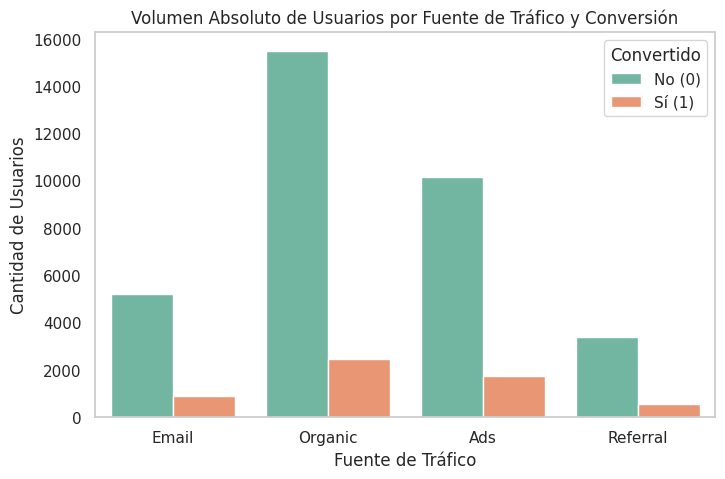

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='traffic_source', hue='converted', palette='Set2')
plt.title('Volumen Absoluto de Usuarios por Fuente de Tráfico y Conversión')
plt.xlabel('Fuente de Tráfico')
plt.ylabel('Cantidad de Usuarios')
plt.legend(title='Convertido', labels=['No (0)', 'Sí (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

El gráfico de volumen absoluto muestra que **Organic** y **Ads** representan las mayores fuentes de volumen total de usuarios en la plataforma. Aunque Organic aporta la mayor cantidad de visitas totales, Ads genera un alto volumen de usuarios convertidos de manera efectiva.

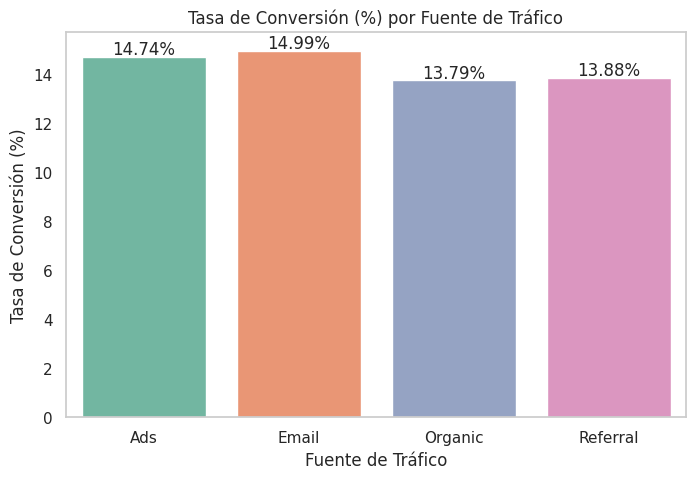

In [31]:
# Gráfico de barras de la tasa de conversión por fuente de tráfico
tasa_fuente = df.groupby('traffic_source')['converted'].mean().reset_index()
tasa_fuente['converted'] = tasa_fuente['converted'] * 100

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=tasa_fuente, x='traffic_source', y='converted', palette='Set2')
plt.title('Tasa de Conversión (%) por Fuente de Tráfico')
plt.xlabel('Fuente de Tráfico')
plt.ylabel('Tasa de Conversión (%)')

for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

El gráfico de proporciones confirma que **Email (14.99%)** y **Ads (14.74%)** registran las tasas de conversión más altas. Aunque Organic aporta más usuarios en términos absolutos, su efectividad porcentual (13.79%) es la más baja, reforzando los hallazgos de la prueba Chi-cuadrado sobre la efectividad de los canales directos/pagados.

### Relación entre el tipo de usuario y la conversión

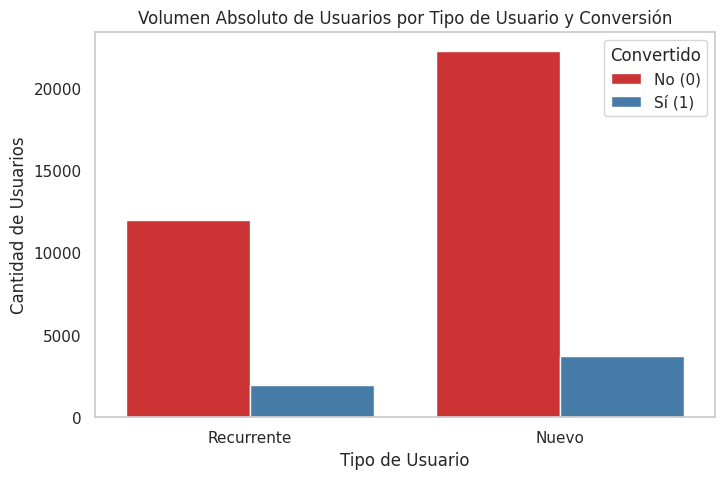

In [29]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='user_type', hue='converted', palette='Set1')
plt.title('Volumen Absoluto de Usuarios por Tipo de Usuario y Conversión')
plt.xlabel('Tipo de Usuario')
plt.ylabel('Cantidad de Usuarios')
plt.legend(title='Convertido', labels=['No (0)', 'Sí (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

En términos absolutos, la mayoría del tráfico proviene de **Usuarios Nuevos**, aportando también el volumen más alto de conversiones totales (3,738 conversiones) en comparación con los usuarios recurrentes (1,968 conversiones).

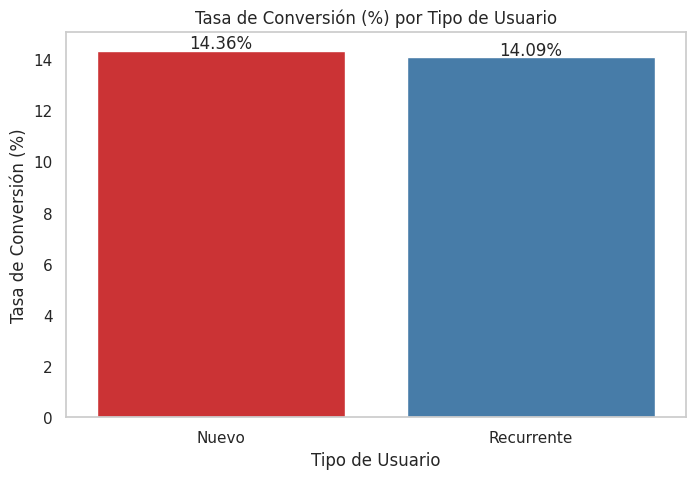

In [30]:
tasa_user = df.groupby('user_type')['converted'].mean().reset_index()
tasa_user['converted'] = tasa_user['converted'] * 100

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=tasa_user, x='user_type', y='converted', palette='Set1')
plt.title('Tasa de Conversión (%) por Tipo de Usuario')
plt.xlabel('Tipo de Usuario')
plt.ylabel('Tasa de Conversión (%)')

for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

El gráfico de tasa de conversión evidencia un comportamiento homogéneo entre ambos segmentos: los **Usuarios Nuevos** convierten al **14.36%** y los **Usuarios Recurrentes** al **14.09%**. Esta diferencia mínima de 0.27% concuerda con la prueba Chi-cuadrado previa, confirmando que la probabilidad de conversión es independiente del tipo de usuario.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

* **Gasto medio alto en ambas versiones:** Los usuarios que realizan una compra gastan en promedio montos similares en ambas variantes de la landing page.
* **Sin diferencia estadísticamente significativa:** La prueba t de Student o Mann-Whitney U no mostró diferencias estadísticamente significativas en el ticket promedio entre los compradores de la versión A y la versión B.
* **Interpretación:** La modificación implementada en la Página B no alteró el valor medio de compra ni el comportamiento de gasto de los clientes que deciden convertir; su impacto principal se concentra en el volumen de conversión.

**Tasa de conversión:**
* **Landing A:** Registró una tasa de conversión del **12.57%** (2,512 conversiones de 19,982 usuarios).
* **Landing B:** Alcanzó una tasa de conversión del **15.96%** (3,194 conversiones de 20,018 usuarios).
* **Interpretación:** Existe una diferencia estadísticamente significativa ($p < 0.05$). La Página B supera a la Página A con un incremento absoluto de **3.38 puntos porcentuales** y una mejora relativa del **26.9%** en el número de compras, consolidándose como la versión ganadora del experimento A/B.

---

#### 📊 **Segmentación por fuente de tráfico**
* **Rendimiento por canal:** Los canales de comunicación directa y pagada obtuvieron las mejores tasas de conversión: **Email (14.99%)** y **Ads (14.74%)**, superando a **Referral (13.88%)** y **Organic (13.79%)**.
* **Interpretación:** La prueba Chi-cuadrado confirmó una relación estadísticamente significativa entre el canal de origen y la probabilidad de conversión ($p = 0.0341$). Los usuarios que provienen de campañas dirigidas (Email y Anuncios) muestran mayor predisposición a la compra que el tráfico orgánico.
  
 ---

#### 📊 **Segmentación por tipo de usuario**
* **Comportamiento por perfil:** Los **Usuarios Nuevos** registraron una tasa de conversión del **14.36%**, mientras que los **Usuarios Recurrentes** registraron un **14.09%**.
* **Interpretación:** La prueba Chi-cuadrado no mostró diferencias estadísticamente significativas ($p = 0.4736$). La intención de compra es homogénea entre ambos segmentos, lo que indica que la experiencia en la landing page impacta de igual manera a usuarios primerizos y habituales.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:** 

* **Implementar de forma definitiva la Landing B:** Desplegar la versión B como la página predeterminada para el 100% del tráfico, lo cual generará un aumento sostenido en el volumen total de conversiones sin perjudicar el ticket promedio.
* **Reasignar presupuesto de marketing hacia Email y Ads:** Incrementar la inversión en captación y retención a través de Email Marketing y anuncios pagados, ya que demostraron ser los canales con mayor efectividad de conversión.
* **Optimizar la estrategia de tráfico orgánico:** Rediseñar la experiencia de llegada para los usuarios provenientes de búsquedas orgánicas, aplicando las mejoras de diseño de la Landing B para elevar su tasa de conversión al nivel de los canales pagados.